DFtotal shape: (257673, 7)
Unique original classes: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9]

Macro-class distribution:
attack_cat
DoS-Fuzzers        40599
Generic            58871
Normal             93000
System-Exploits    48365
Worm-Recon         16838
Name: count, dtype: int64

Macro-class integer mapping:
  0 -> DoS-Fuzzers
  1 -> Generic
  2 -> Normal
  3 -> System-Exploits
  4 -> Worm-Recon
Macro-class distribution:
attack_cat
0    40599
1    58871
2    93000
3    48365
4    16838
Name: count, dtype: int64

Train: (206138, 6) Test: (51535, 6)
x_train: (206138, 6) x_test: (51535, 6)
Class weights: {0: 1.269361741432926, 1: 0.8753763509353037, 2: 0.5541344086021506, 3: 1.0655329267031945, 4: 3.0606978470675577}
X_train_cnn: (206138, 6, 1)
X_test_cnn:  (51535, 6, 1)
num_classes: 5
n_features:  6


2026-10-16 10:59:18.193836: I tensorflow/core/util/port.cc:110] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
2026-10-16 10:59:18.218748: I tensorflow/tsl/cuda/cudart_stub.cc:28] Could not find cuda drivers on your machine, GPU will not be used.
2026-10-16 10:59:18.424943: I tensorflow/tsl/cuda/cudart_stub.cc:28] Could not find cuda drivers on your machine, GPU will not be used.
2026-10-16 10:59:18.427378: I tensorflow/core/platform/cpu_feature_guard.cc:182] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
2026-10-16 10:59:19.579215: W tensorflow/compiler/tf2tensorrt/utils/py_utils.cc:38] TF-TRT Warning: Could not fin

Model: "CNN_IDS_designed_16f"
__________________________________________________________________________________________________
 Layer (type)                Output Shape                 Param #   Connected to                  
 Input (InputLayer)          [(None, 6, 1)]               0         []                            
                                                                                                  
 B1_Conv3 (Conv1D)           (None, 6, 32)                128       ['Input[0][0]']               
                                                                                                  
 B1_Conv5 (Conv1D)           (None, 6, 32)                192       ['Input[0][0]']               
                                                                                                  
 B1_Concat (Concatenate)     (None, 6, 64)                0         ['B1_Conv3[0][0]',            
                                                                     'B1_Conv5[

/home/e-ackerson/anaconda3/envs/tf213_only/lib/python3.9/site-packages/keras/src/engine/training.py:3000: UserWarning: You are saving your model as an HDF5 file via `model.save()`. This file format is considered legacy. We recommend using instead the native Keras format, e.g. `model.save('my_model.keras')`.
  saving_api.save_model(


723/725 [============================>.] - ETA: 0s - loss: 0.7578 - accuracy: 0.7033
Epoch 2: val_accuracy improved from 0.70413 to 0.72528, saving model to cnn_designed_16_best.h5
725/725 [==============================] - 15s 21ms/step - loss: 0.7577 - accuracy: 0.7033 - val_loss: 0.6217 - val_accuracy: 0.7253 - lr: 0.0010
Epoch 3/100
725/725 [==============================] - ETA: 0s - loss: 0.7303 - accuracy: 0.7115
Epoch 3: val_accuracy did not improve from 0.72528
725/725 [==============================] - 15s 21ms/step - loss: 0.7303 - accuracy: 0.7115 - val_loss: 0.6298 - val_accuracy: 0.7192 - lr: 0.0010
Epoch 4/100
725/725 [==============================] - ETA: 0s - loss: 0.7092 - accuracy: 0.7178
Epoch 4: val_accuracy improved from 0.72528 to 0.72533, saving model to cnn_designed_16_best.h5
725/725 [==============================] - 16s 22ms/step - loss: 0.7092 - accuracy: 0.7178 - val_loss: 0.5915 - val_accuracy: 0.7253 - lr: 0.0010
Epoch 5/100
723/725 [===================

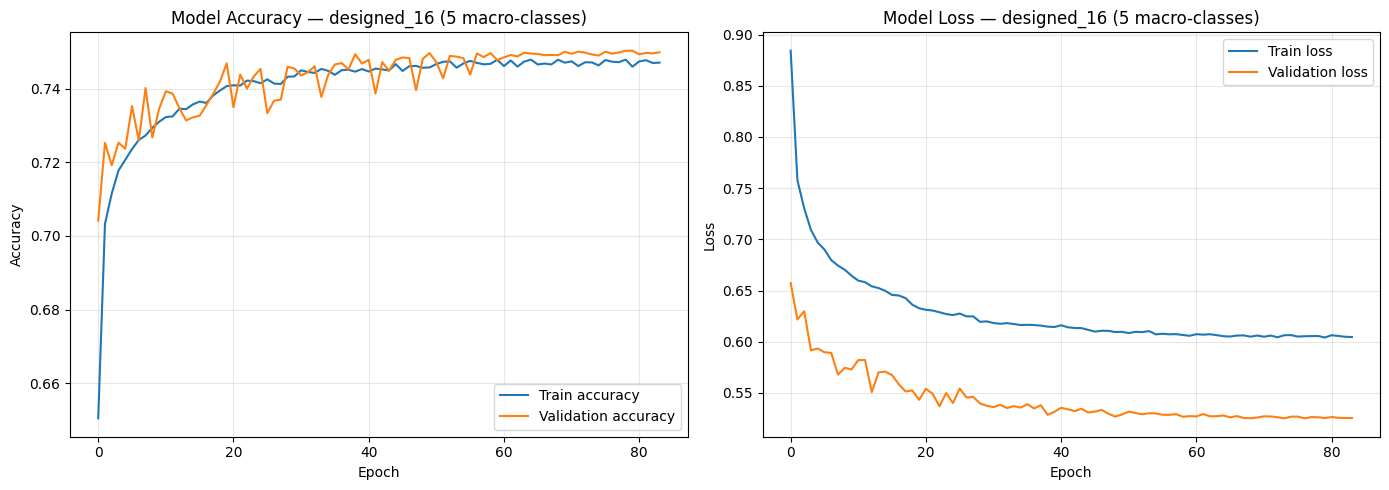

Confusion matrix labels: ['DoS-Fuzzers', 'Generic', 'Normal', 'System-Exploits', 'Worm-Recon']


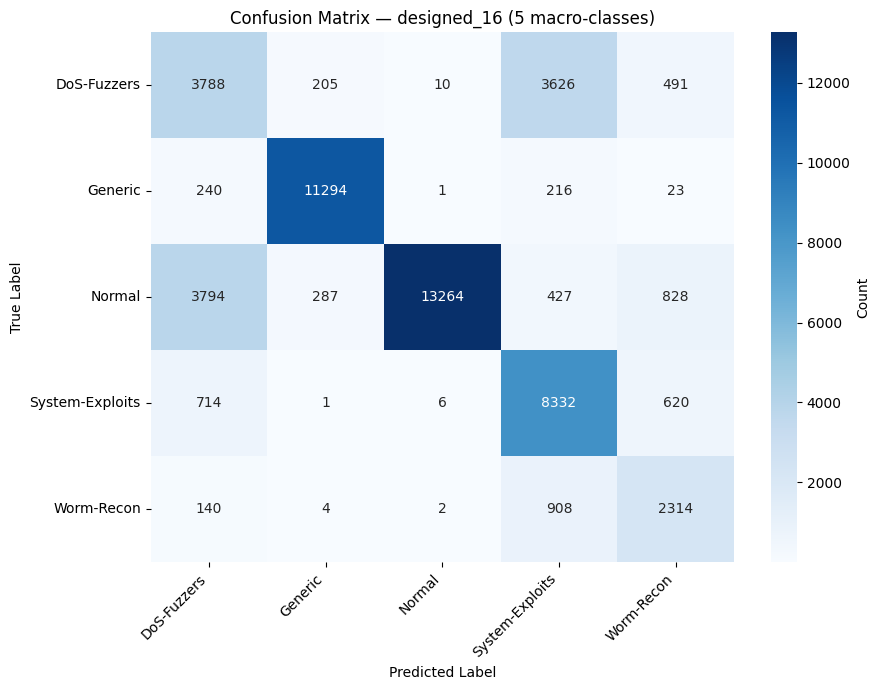


Saved to cnn_results_designed_16_macro5.csv


,feature_set,n_features,n_classes,accuracy,precision_weighted,recall_weighted,f1_weighted,f1_macro,train_time_s,inference_time_s,inference_ms_per_sample,model_params
0,designed_16_macro5,6,5,0.756612,0.799166,0.756612,0.764856,0.713184,961.371705,2.173823,0.042181,59077


In [2]:
# ============================================================================
# DATA LOADING 
# ============================================================================
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
pd.set_option('display.max_columns', 100)

# Load the optimised features CSV (all 257,673 samples, 6 PCs + target)
dftotal = pd.read_csv('/home/e-ackerson/GIT_hub/Research_Project/DL_models/CNN_models_evals/16_optimised_6/16_optimal_features_ids')

# Drop the unnamed index column if present
if 'Unnamed: 0' in dftotal.columns:
    dftotal = dftotal.drop(columns=['Unnamed: 0'])

DFtotal = dftotal[[
    'Fused_proto_PC3', 'Fused_dur_PC2', 'Fused_proto_PC1',
    'Fused_proto_PC9', 'Fused_proto_PC6', 'Fused_dur_PC1',
    'attack_cat'
]]

print("DFtotal shape:", DFtotal.shape)
print("Unique original classes:", sorted(DFtotal['attack_cat'].unique()))

# ============================================================================
# APPLY MACRO-CLASS MAPPING
# ============================================================================
# Original 10 classes (alphabetical integer encoding):
#   0 Analysis, 1 Backdoor, 2 DoS, 3 Exploits, 4 Fuzzers,
#   5 Generic, 6 Normal, 7 Reconnaissance, 8 Shellcode, 9 Worms

category_map = {
    2: 'DoS-Fuzzers',
    4: 'DoS-Fuzzers',
    1: 'System-Exploits',
    3: 'System-Exploits',
    8: 'System-Exploits',
    9: 'Worm-Recon',
    0: 'Worm-Recon',
    7: 'Worm-Recon',
    5: 'Generic',
    6: 'Normal'
}

DFtotal['attack_cat'] = DFtotal['attack_cat'].map(category_map)

print("\nMacro-class distribution:")
print(DFtotal['attack_cat'].value_counts().sort_index())

# Re-encode macro-classes to contiguous integers (0-4)
from sklearn.preprocessing import LabelEncoder

macro_encoder = LabelEncoder()
DFtotal['attack_cat'] = macro_encoder.fit_transform(DFtotal['attack_cat'])

print("\nMacro-class integer mapping:")
for i, name in enumerate(macro_encoder.classes_):
    print(f"  {i} -> {name}")


print("Macro-class distribution:")
print(DFtotal['attack_cat'].value_counts().sort_index())
# ============================================================================
# TRAIN / TEST SPLIT
# ============================================================================
from sklearn.model_selection import train_test_split

y = DFtotal['attack_cat']
x = DFtotal.drop(columns={'attack_cat'})

xtrain_val, xtest, ytrain_val, ytest = train_test_split(
    x, y, test_size=0.2, random_state=42, stratify=y
)

print("\nTrain:", xtrain_val.shape, "Test:", xtest.shape)


# ============================================================================
# FEATURE ENGINEERING
# ============================================================================
FEATURES = [
    'Fused_proto_PC3', 'Fused_dur_PC2', 'Fused_proto_PC1',
    'Fused_proto_PC9', 'Fused_proto_PC6', 'Fused_dur_PC1',
]

x_train = xtrain_val[FEATURES].copy()
x_test  = xtest[FEATURES].copy()

print("x_train:", x_train.shape, "x_test:", x_test.shape)


# ============================================================================
# CLASS WEIGHTS
# ============================================================================
from sklearn.utils.class_weight import compute_class_weight

classes = np.unique(ytrain_val)
class_weights_array = compute_class_weight(
    class_weight='balanced',
    classes=classes,
    y=ytrain_val
)
class_weights = dict(zip(classes, class_weights_array))
print("Class weights:", class_weights)


# ============================================================================
# RESHAPE FOR 1D-CNN
# ============================================================================
y_train = ytrain_val.values
y_test  = ytest.values
num_classes = len(np.unique(y_train))

n_features = x_train.shape[1]

X_train_cnn = x_train.values.reshape(-1, n_features, 1)
X_test_cnn  = x_test.values.reshape(-1, n_features, 1)

print("X_train_cnn:", X_train_cnn.shape)
print("X_test_cnn: ", X_test_cnn.shape)
print("num_classes:", num_classes)
print("n_features: ", n_features)


# ============================================================================
# CNN MODEL ARCHITECTURE
# ============================================================================
import tensorflow as tf
from tensorflow.keras.layers import (
    Input, Conv1D, MaxPooling1D, GlobalAveragePooling1D,
    Dense, Dropout, Concatenate, BatchNormalization
)
from tensorflow.keras.models import Model
from tensorflow.keras.optimizers import Adam

np.random.seed(42)
tf.random.set_seed(42)

input_layer = Input(shape=(n_features, 1), name="Input")

# -------- Block 1 --------
b1_conv3 = Conv1D(32, 3, padding='same', activation='relu', name="B1_Conv3")(input_layer)
b1_conv5 = Conv1D(32, 5, padding='same', activation='relu', name="B1_Conv5")(input_layer)
b1 = Concatenate(axis=-1, name="B1_Concat")([b1_conv3, b1_conv5])
b1 = BatchNormalization(name="B1_BN")(b1)
b1 = Dropout(0.3, name="B1_Drop")(b1)

# -------- Block 2 --------
b2_conv3 = Conv1D(64, 3, padding='same', activation='relu', name="B2_Conv3")(b1)
b2_conv5 = Conv1D(64, 5, padding='same', activation='relu', name="B2_Conv5")(b1)
b2 = Concatenate(axis=-1, name="B2_Concat")([b2_conv3, b2_conv5])
b2 = BatchNormalization(name="B2_BN")(b2)
b2 = MaxPooling1D(pool_size=2, name="B2_Pool")(b2)
b2 = Dropout(0.3, name="B2_Drop")(b2)

# -------- Aggregation --------
gap = GlobalAveragePooling1D(name="GAP")(b2)

# -------- Classification Head --------
head = Dense(128, activation='relu', name="Dense_128")(gap)
head = Dropout(0.4, name="Head_Drop1")(head)
head = Dense(64, activation='relu', name="Dense_64")(head)
head = Dropout(0.3, name="Head_Drop2")(head)
output = Dense(num_classes, activation='softmax', name="Output")(head)

model = Model(inputs=input_layer, outputs=output, name="CNN_IDS_designed_16f")
model.compile(
    optimizer=Adam(learning_rate=1e-3),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)
model.summary()


# ============================================================================
# CALLBACKS
# ============================================================================
from tensorflow.keras.callbacks import ModelCheckpoint, EarlyStopping, ReduceLROnPlateau

checkpoint = ModelCheckpoint(
    "cnn_designed_16_best.h5",
    monitor='val_accuracy',
    save_best_only=True,
    verbose=1
)

early_stop = EarlyStopping(
    monitor='val_loss',
    patience=10,
    restore_best_weights=True,
    verbose=1
)

reduce_lr = ReduceLROnPlateau(
    monitor='val_loss',
    factor=0.5,
    patience=5,
    min_lr=1e-6,
    verbose=1
)


# ============================================================================
# TRAINING
# ============================================================================
import time

start_train = time.time()

history = model.fit(
    X_train_cnn, y_train,
    epochs=100,
    batch_size=256,
    validation_split=0.1,
    class_weight=class_weights,
    callbacks=[checkpoint, early_stop, reduce_lr],
    verbose=1
)

train_time = time.time() - start_train
print(f"\nTraining time: {train_time:.2f} s")


# ============================================================================
# COMPLETE TRAINING HISTORY
# ============================================================================
print("\n" + "=" * 78)
print("COMPLETE TRAINING HISTORY — designed_16 (5 macro-classes)")
print("=" * 78)
print(f"{'Epoch':<8}{'Train Acc':<14}{'Val Acc':<14}{'Train Loss':<14}{'Val Loss':<14}")
print("-" * 78)

for epoch in range(len(history.history['accuracy'])):
    print(
        f"{epoch + 1:<8}"
        f"{history.history['accuracy'][epoch]:<14.4f}"
        f"{history.history['val_accuracy'][epoch]:<14.4f}"
        f"{history.history['loss'][epoch]:<14.4f}"
        f"{history.history['val_loss'][epoch]:<14.4f}"
    )

print("=" * 78)
print(f"Total epochs run : {len(history.history['accuracy'])}")

if len(history.history['val_accuracy']) > 0:
    print(f"Best val accuracy: {max(history.history['val_accuracy']):.4f} "
          f"(epoch {np.argmax(history.history['val_accuracy']) + 1})")
    print(f"Best val loss    : {min(history.history['val_loss']):.4f} "
          f"(epoch {np.argmin(history.history['val_loss']) + 1})")
else:
    print("No training history available.")

print("=" * 78)


# ============================================================================
# EVALUATION
# ============================================================================
from sklearn.metrics import (
    classification_report, confusion_matrix,
    accuracy_score, precision_score, recall_score, f1_score
)
import seaborn as sns

start_infer = time.time()
y_pred_proba = model.predict(X_test_cnn, verbose=0)
infer_time = time.time() - start_infer
per_sample_ms = (infer_time / len(X_test_cnn)) * 1000

y_pred = np.argmax(y_pred_proba, axis=1)

acc  = accuracy_score(y_test, y_pred)
prec = precision_score(y_test, y_pred, average='weighted', zero_division=0)
rec  = recall_score(y_test, y_pred, average='weighted', zero_division=0)
f1w  = f1_score(y_test, y_pred, average='weighted', zero_division=0)
f1m  = f1_score(y_test, y_pred, average='macro', zero_division=0)

print("\n" + "="*60)
print("TEST SET PERFORMANCE — designed_16 (6 PCs, 5 macro-classes)")
print("="*60)
print(f"Accuracy      : {acc:.4f}")
print(f"Precision (W) : {prec:.4f}")
print(f"Recall (W)    : {rec:.4f}")
print(f"F1 (Weighted) : {f1w:.4f}")
print(f"F1 (Macro)    : {f1m:.4f}")
print(f"Training time : {train_time:.2f} s")
print(f"Inference time: {infer_time:.2f} s ({per_sample_ms:.4f} ms/sample)")
print(f"Model params  : {model.count_params()}")

print("\n===== CLASSIFICATION REPORT =====")
print(classification_report(y_test, y_pred, digits=4, zero_division=0))


# ============================================================================
# TRAINING AND VALIDATION CURVES
# ============================================================================
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(history.history['accuracy'], label='Train accuracy')
axes[0].plot(history.history['val_accuracy'], label='Validation accuracy')
axes[0].set_title('Model Accuracy — designed_16 (5 macro-classes)')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Accuracy')
axes[0].legend(loc='lower right')
axes[0].grid(alpha=0.3)

axes[1].plot(history.history['loss'], label='Train loss')
axes[1].plot(history.history['val_loss'], label='Validation loss')
axes[1].set_title('Model Loss — designed_16 (5 macro-classes)')
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('Loss')
axes[1].legend(loc='upper right')
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.savefig('training_curves_designed_16.png', dpi=300)
plt.show()


# ============================================================================
# CONFUSION MATRIX
# ============================================================================
# Use the macro-class names in the order produced by macro_encoder
class_names = list(macro_encoder.classes_)
print("Confusion matrix labels:", class_names)

cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(9, 7))
sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=class_names,
    yticklabels=class_names,
    cbar_kws={'label': 'Count'}
)
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.title('Confusion Matrix — designed_16 (5 macro-classes)')
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.savefig('confusion_designed_16.png', dpi=300)
plt.show()


# ============================================================================
# SAVE RESULTS
# ============================================================================
results = pd.DataFrame([{
    'feature_set': 'designed_16_macro5',
    'n_features': n_features,
    'n_classes': num_classes,
    'accuracy': acc,
    'precision_weighted': prec,
    'recall_weighted': rec,
    'f1_weighted': f1w,
    'f1_macro': f1m,
    'train_time_s': train_time,
    'inference_time_s': infer_time,
    'inference_ms_per_sample': per_sample_ms,
    'model_params': model.count_params()
}])

results.to_csv('cnn_results_designed_16_macro5.csv', index=False)
print("\nSaved to cnn_results_designed_16_macro5.csv")
results

In [5]:
# ============================================================================
# INFERENCE LATENCY BENCHMARK — designed_16 (isolated measurement)
# ============================================================================
import time

# Warm-up runs (not measured — they prime the graph)
_ = model.predict(X_test_cnn[:200], verbose=0, batch_size=256)
_ = model.predict(X_test_cnn[:200], verbose=0, batch_size=256)

# Measured runs — repeat 5 times and take the median
latencies = []
for run in range(5):
    start = time.time()
    _ = model.predict(X_test_cnn, verbose=0, batch_size=256)
    elapsed = time.time() - start
    per_sample_ms = (elapsed / len(X_test_cnn)) * 1000
    latencies.append(per_sample_ms)
    print(f"Run {run + 1}: {per_sample_ms:.4f} ms/sample")

median_latency = sorted(latencies)[len(latencies) // 2]
mean_latency = sum(latencies) / len(latencies)

print("\n" + "="*60)
print("INFERENCE LATENCY — designed_16 (isolated benchmark)")
print("="*60)
print(f"Runs         : {len(latencies)}")
print(f"Median       : {median_latency:.4f} ms/sample")
print(f"Mean         : {mean_latency:.4f} ms/sample")
print(f"Throughput   : {1000 / median_latency:.0f} samples/second")
print(f"Batch size   : 256")
print(f"Test samples : {len(X_test_cnn)}")

Run 1: 0.0109 ms/sample
Run 2: 0.0110 ms/sample
Run 3: 0.0137 ms/sample
Run 4: 0.0110 ms/sample
Run 5: 0.0116 ms/sample

INFERENCE LATENCY — designed_16 (isolated benchmark)
Runs         : 5
Median       : 0.0110 ms/sample
Mean         : 0.0116 ms/sample
Throughput   : 90662 samples/second
Batch size   : 256
Test samples : 51535


In [4]:
# ============================================================================
# COMPLETE TRAINING HISTORY
# ============================================================================
print("\n" + "=" * 78)
print("COMPLETE TRAINING HISTORY — designed_16")
print("=" * 78)
print(f"{'Epoch':<8}{'Train Acc':<14}{'Val Acc':<14}{'Train Loss':<14}{'Val Loss':<14}")
print("-" * 78)

for epoch in range(len(history.history['accuracy'])):
    print(
        f"{epoch + 1:<8}"
        f"{history.history['accuracy'][epoch]:<14.4f}"
        f"{history.history['val_accuracy'][epoch]:<14.4f}"
        f"{history.history['loss'][epoch]:<14.4f}"
        f"{history.history['val_loss'][epoch]:<14.4f}"
    )

print("=" * 78)
print(f"Total epochs run : {len(history.history['accuracy'])}")

if len(history.history['val_accuracy']) > 0:
    print(f"Best val accuracy: {max(history.history['val_accuracy']):.4f} "
          f"(epoch {np.argmax(history.history['val_accuracy']) + 1})")
    print(f"Best val loss    : {min(history.history['val_loss']):.4f} "
          f"(epoch {np.argmin(history.history['val_loss']) + 1})")
else:
    print("No training history available.")

print("=" * 78)


COMPLETE TRAINING HISTORY — designed_16
Epoch   Train Acc     Val Acc       Train Loss    Val Loss      
------------------------------------------------------------------------------
1       0.6505        0.7041        0.8843        0.6572        
2       0.7033        0.7253        0.7577        0.6217        
3       0.7115        0.7192        0.7303        0.6298        
4       0.7178        0.7253        0.7092        0.5915        
5       0.7207        0.7237        0.6969        0.5934        
6       0.7236        0.7353        0.6900        0.5897        
7       0.7261        0.7260        0.6797        0.5890        
8       0.7273        0.7402        0.6744        0.5678        
9       0.7294        0.7267        0.6703        0.5745        
10      0.7310        0.7345        0.6645        0.5729        
11      0.7323        0.7393        0.6596        0.5820        
12      0.7325        0.7387        0.6581        0.5821        
13      0.7346        0.7347       